##Dataset utilizado:

- Nome: Nintendo Games
- Fonte: Kraggle
- Link: [https://www.kaggle.com/datasets/joebeachcapital/nintendo-games]

# Projeto de Análise de Dados: Jogos da Nintendo

##  Perguntas exploratórias:

1. Qual é o jogo com a maior nota dos críticos (`meta_score`)?
2. Quais são os 5 desenvolvedores (`developers`) mais frequentes no catálogo?
3. Qual é a plataforma (`platform`) com a maior média de notas dos críticos?
4. Qual é a classificação indicativa (`esrb_rating`) mais comum nos jogos?
5. Qual é a correlação entre a nota dos críticos (`meta_score`) e a nota dos usuários (`user_score`)?

In [ ]:
# Importanto as bibliotecas:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/NintendoGames.csv')

# Análise exploratória e limpeza:

In [48]:
df.head()

,meta_score,title,platform,date,user_score,link,esrb_rating,developers,genres
0,NaN,Super Mario RPG,Switch,"Nov 17, 2023",NaN,/game/switch/super-mario-rpg,E,['Nintendo'],"['Role-Playing', 'Japanese-Style']"
1,NaN,WarioWare: Move It!,Switch,"Nov 3, 2023",NaN,/game/switch/warioware-move-it!,RP,['Intelligent Systems'],"['Miscellaneous', 'Party / Minigame']"
2,NaN,Super Mario Bros. Wonder,Switch,"Oct 20, 2023",NaN,/game/switch/super-mario-bros-wonder,E,['Nintendo'],"['Action', 'Platformer', '2D']"
3,NaN,Detective Pikachu Returns,Switch,"Oct 6, 2023",NaN,/game/switch/detective-pikachu-returns,NaN,['Creatures Inc.'],"['Adventure', '3D', 'Third-Person']"
4,NaN,Fae Farm,Switch,"Sep 8, 2023",NaN,/game/switch/fae-farm,E10+,['Phoenix Labs'],"['Simulation', 'Virtual', 'Virtual Life']"


In [42]:
# Informações dos dados:

print("--- INFORMAÇÕES DO DATAFRAME ---\n")
df.info()
print("\n--- LINHAS x COLUNAS ---\n")
print(df.shape)
print('\n *** VERIFICAÇÃO DE LIMPEZA ***')
print("\n--- QUANTIDADE DE VALORES NULOS POR COLUNA ---\n")
print(df.isnull().sum())
total_duplicadas = df.duplicated().sum()
print(f"\nTotal de linhas duplicadas: {total_duplicadas}")




--- INFORMAÇÕES DO DATAFRAME ---

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1094 entries, 0 to 1093
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   meta_score   709 non-null    float64
 1   title        1094 non-null   object 
 2   platform     1094 non-null   object 
 3   date         1094 non-null   object 
 4   user_score   856 non-null    float64
 5   link         1094 non-null   object 
 6   esrb_rating  972 non-null    object 
 7   developers   1091 non-null   object 
 8   genres       1094 non-null   object 
dtypes: float64(2), object(7)
memory usage: 77.1+ KB

--- LINHAS x COLUNAS ---

(1094, 9)

 *** VERIFICAÇÃO DE LIMPEZA ***

--- QUANTIDADE DE VALORES NULOS POR COLUNA ---

meta_score     385
title            0
platform         0
date             0
user_score     238
link             0
esrb_rating    122
developers       3
genres           0
dtype: int64

Total de linhas duplicadas: 0


#Respondendo algumas perguntas:

##1. Qual é o jogo com a maior nota dos críticos (`meta_score`)?

In [46]:
df.loc[df['meta_score'].idxmax(), ['title', 'meta_score']]

,1060
title,The Legend of Zelda: Ocarina of Time
meta_score,99.0


##O jogo com o maior nota(Meta score) do dataset é The Legend of Zelda: Ocarina of Time, com nota 99,0

## 2. Quais são os 5 desenvolvedores (`developers`) mais frequentes no catálogo?

In [47]:
df['developers'].value_counts().head()

,count
developers,
['Nintendo'],354
['Intelligent Systems'],95
['Game Freak'],45
['HAL Labs'],34
['Level 5'],27


O 5 desenvolvedores que produzem mais jogos são respectivamente: Nintendo, Intelligent Systems, Game Freak, HAL Labs e Level 5.

## 3. Qual é a plataforma (`platform`) com a maior média de notas dos críticos?

In [52]:
df.groupby('platform')['meta_score'].mean().sort_values(ascending=False).head(1)

,meta_score
platform,
N64,83.967742


A plataforma(videogame) com a maior média de notas dos críticos é o Nintendo 64.

## 4. Qual é a classificação indicativa (`esrb_rating`) mais comum nos jogos?

In [53]:
df['esrb_rating'].value_counts().head()

,count
esrb_rating,
E,660
T,150
E10+,142
M,15
RP,5


A classificação indicativa mais comum é a E(equivale a classificação Livre no Brasil).

## 5. Qual é a correlação entre a nota dos críticos (`meta_score`) e a nota dos usuários (`user_score`)?

In [57]:
round(df[['meta_score', 'user_score']].corr().iloc[0,1] ,2)

np.float64(0.63)

Existe uma correlação positiva moderada (0.63) entre a nota dos críticos e a nota dos usuários. Como o valor é positivo e está mais próximo de 1 do que de 0, isso indica que, no geral, os jogos bem avaliados pela crítica especializada também tendem a agradar o público.

# Gráficos

## Top 5 desenvolvedores por quantidade de jogos desenvolvidos:

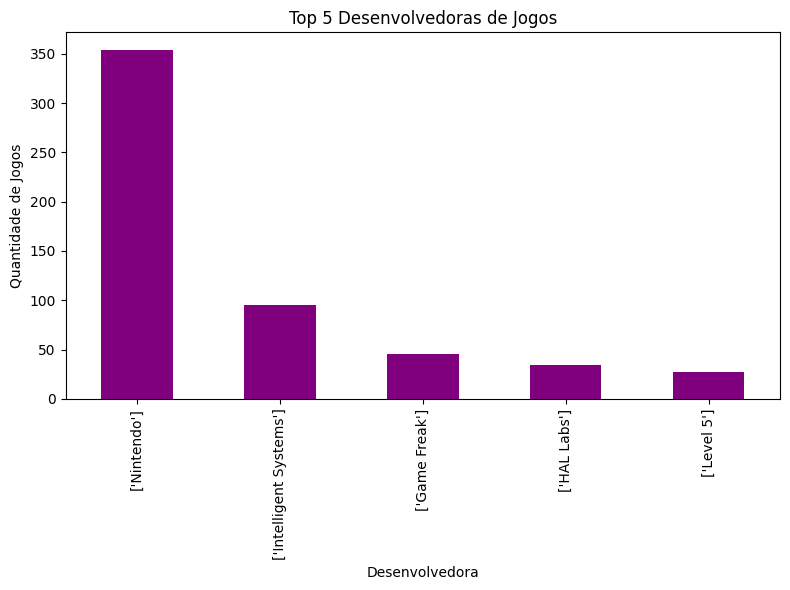

In [63]:
df['developers'].value_counts().head(5).plot(kind='bar', color='purple', figsize=(8, 6))
plt.title('Top 5 Desenvolvedoras de Jogos')
plt.xlabel('Desenvolvedora')
plt.ylabel('Quantidade de Jogos')
plt.tight_layout()
plt.show()

## Demonstrativo da correlação entre a nota dos críticos e dos usuários(0,63):

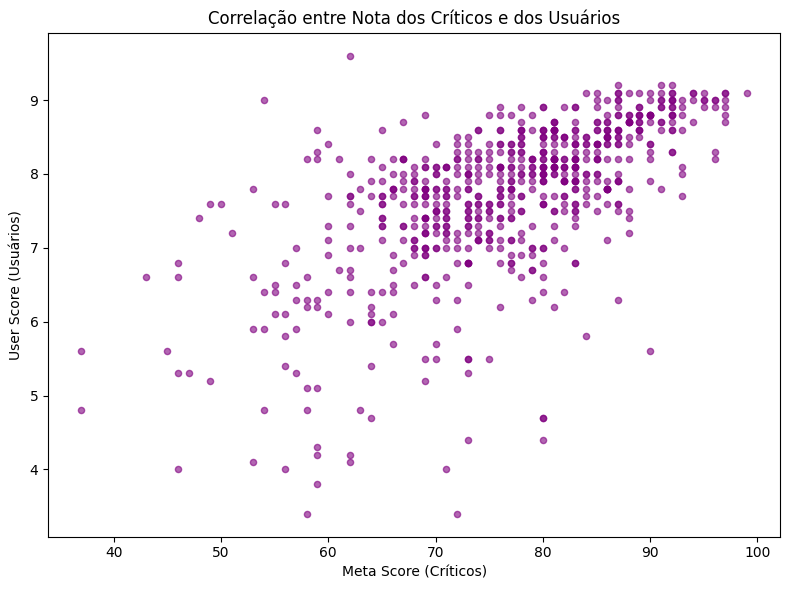

In [64]:
df.plot(kind='scatter', x='meta_score', y='user_score', color='purple', alpha=0.6, figsize=(8, 6))
plt.title('Correlação entre Nota dos Críticos e dos Usuários')
plt.xlabel('Meta Score (Críticos)')
plt.ylabel('User Score (Usuários)')
plt.tight_layout()
plt.show()

## Distribuição das classificações indicativas:

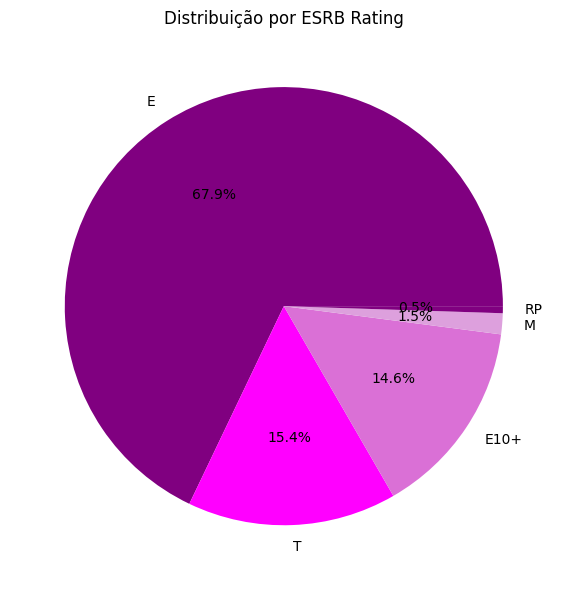

In [65]:
df['esrb_rating'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(8, 6), colors=['purple', 'magenta', 'orchid', 'plum'])
plt.title('Distribuição por ESRB Rating')
plt.ylabel('') # Remove o rótulo lateral que fica feio no gráfico de pizza
plt.tight_layout()
plt.show()

##**--- Conclusão ---**

### **Introdução/Objetivo:**
Análise exploratória do dataset de jogos da Nintendo para entender tendências de mercado, notas, plataformas e desenvolvedoras.

## **Principais Descobertas:**

* **Desenvolvedoras Líderes:** A liderança no volume de jogos fica concentrado nas mãos da própria Nintendo.

* **Classificação Indicativa**: Predominância de jogos voltados para o público geral.

* **Relação Crítica vs. Público:** A correlação positiva moderada (0.63) provando que a opinião da crítica especializada e dos jogadores caminha em sintonia.

## **Conclusão geral:**

A análise dos dados mostra um catálogo alinhado entre o que a crítica avalia e o que o público consome. Isso é comprovado pela correlação positiva moderada de 0.63 entre as notas dos críticos e dos usuários, indicando que jogos bem avaliados pela mídia costumam agradar aos jogadores. Além disso, os dados revelam um foco claro no público geral, devido à predominância da classificação ESRB "E"(Livre), e a própria Nintendo tem forte participação no desenvolvimento dos jogos para suas plataformas.